# Multi-Agent Printer Support Team

## 1. Prerequisites and configuration

In [ ]:
pip install langgraph langchain-core langchain-openai requests python-dotenv colorama pydantic fastapi "uvicorn[standard]"


**Start the separate warranty API before running this notebook.** 

In a terminal in the directory containing `server.py`, run:


```bash
python -m uvicorn server:app --reload --host 127.0.0.1 --port 8000

# if you use uv:
uv run uvicorn server:app --reload --host 127.0.0.1 --port 8000
```

Keep the terminal open. The notebook **does not start a FastAPI server**. If Jupyter runs in a remote environment, `127.0.0.1` may not point to your local machine; set `WARRANTY_API_BASE_URL` to an address reachable from the notebook environment.


In [8]:
import os
import requests
from dotenv import load_dotenv


load_dotenv(override=True)

model = os.getenv("OPENAI_MODEL", "llama3.1:8b") #  "phi4-mini" "qwen2.5:7b" "tencent/hy3:free"  "gpt-4.1-mini"

BASE = os.getenv("WARRANTY_API_BASE_URL", "http://127.0.0.1:8000").rstrip("/")
COMPANY = "Northstar Printer Support"
print("Warranty API:", BASE)

Warranty API: http://127.0.0.1:8000


## 2. Verify the external warranty API

The warranty provider exposes **one business endpoint**: `GET /warranty/{device_id}`. Its response calculates `covered` from the expiry date. **HTTP 404** means no record was found—not proof that the warranty expired.

This is a one-time setup check. **It is not an agent warranty lookup.** During customer calls, the API is accessed only if the first agent routes the request to the warranty specialist.


In [9]:
try:
    health = requests.get(f"{BASE}/openapi.json", timeout=5)
    health.raise_for_status()
except requests.RequestException as exc:
    raise RuntimeError(
        f"Cannot reach the warranty API at {BASE}. Start it in a separate terminal:\n"
        "python -m uvicorn warranty_api:app --reload --port 8000\n"
        "(Use server:app if the filename is server.py.)"
    ) from exc

print("API is reachable.")
print("Swagger:", f"{BASE}/docs")
print("Available paths:", list(health.json().get("paths", {})))


API is reachable.
Swagger: http://127.0.0.1:8000/docs
Available paths: ['/warranty/{device_id}']


## 3. Create the warranty tool

Only the warranty specialist will receive this tool. The technical-support agent will **not** be bound to it.


In [10]:
from langchain_core.tools import tool

@tool
def check_warranty(device_id: str) -> dict:
    """
    Look up warranty coverage for a device ID using the external warranty provider.

    Only the warranty specialist will receive this tool.
    The technical-support agent will not be bound to it.
    """
    device_id = device_id.strip().upper()
    try:
        response = requests.get(f"{BASE}/warranty/{device_id}", timeout=5)
        if response.status_code == 404:
            return {
                "device_id": device_id,
                "status": "unverified",
                "error": "unknown_device",
                "message": "No warranty record found for this device.",
            }
        response.raise_for_status()
        return response.json()
    except requests.RequestException as exc:
        return {
            "device_id": device_id,
            "status": "unavailable",
            "error": "api_unavailable",
            "detail": type(exc).__name__,
        }

print(check_warranty.invoke({"device_id": "PRINTER-1001"}))

{'device_id': 'PRINTER-1001', 'expires': '2028-12-31', 'covered': True, 'checked_on': '2026-11-01'}


## 4. Define technical guidance and the first agent's decision

For this **fictional teaching example**, the support team uses the following simplified policy:

| Issue | Interpretation | Expected route |
|---|---|---|
| **E102** | Paper jam / paper-path obstruction; guided checks possible | Technical support |
| **E205** | Firmware/update issue; guided checks possible | Technical support |
| **Connection failure** | Check cables, Wi-Fi, network and restart | Technical support |
| **E500** | Suspected print-engine hardware failure | Warranty specialist |
| **E900** | Suspected power-system hardware failure | Warranty specialist |
| **Printer stopped working / dead / won't power on** | Suspected hardware failure by default | Warranty specialist |
| **Issue persists after troubleshooting** | Phone support exhausted | Warranty specialist |
| **Explicit warranty or replacement question** | Coverage verification requested | Warranty specialist |
| **Unknown error code** | No approved phone fix available | Warranty specialist |

These codes are **illustrative**, not universal manufacturer error codes. Warranty lookup verifies coverage; it does not approve a replacement.

The **first agent** makes the routing decision and drafts an answer for the technical-only path. A structured response keeps routing separate from the wording of the answer.


In [11]:
from typing import Literal, TypedDict
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from pathlib import Path

llm = ChatOpenAI(
    model=model,
    base_url="http://localhost:11434/v1",  #"https://openrouter.ai/api/v1",
    api_key="olama",  # os.getenv("OPENROUTER_API_KEY"),
    temperature=0)

# Load technical support guidance from an external text file
GUIDANCE_FILE = Path("support_guidance.txt")

SUPPORT_GUIDANCE = GUIDANCE_FILE.read_text(encoding="utf-8")

class TriageDecision(BaseModel):
    route: Literal["technical", "warranty"] = Field(
        description="technical if safe approved phone guidance suffices; otherwise warranty"
    )
    reason: str = Field(description="Short explanation of why this route was selected.")
    technical_answer: str = Field(
        description="Phone troubleshooting response for the technical route; empty for warranty."
    )

triage_model = llm.with_structured_output(TriageDecision)

TRIAGE_PROMPT = f"""You are the FIRST support agent at {COMPANY}.
Decide whether you can handle the caller's request by phone or must send it to
the warranty specialist.

Use ONLY this support policy:
{SUPPORT_GUIDANCE}

Routing rules, in priority order:
1. Explicit coverage/replacement requests, known hardware failure codes E500/E900,
   printer stopped working or not powering on, unresolved attempts, and unknown
   error codes -> route='warranty'.
2. E102, E205, and ordinary connection problems with approved safe phone steps,
   and no sign of failure or unresolved attempts -> route='technical'.
3. If the problem cannot be confidently solved using the approved guidance,
   default to route='warranty'.

For route='technical', write helpful concise step-by-step spoken guidance.
Do not mention warranty status or call any API. Do not say the problem is definitely
fixed: ask the customer to try the steps and call back if the issue persists.
For route='warranty', do not answer or ask anything, leave technical_answer empty.
If the original message inform the device ID pass it to the warranty.
The device ID format are `PRINTER-Numbers`, or `SCANNER-Numbers`.
Do not request warranty checks for straightforward phone-solvable problems.
"""

## 5. warranty specialist's graph with tool calling

The warranty specialist is activated **only after the technical agent chooses the warranty route**. It must use `check_warranty` for coverage questions with a device ID, and it must distinguish *expired*, *covered*, *unverified*, and *service unavailable*.


In [12]:
warranty_model = llm.bind_tools([check_warranty])

def warranty_agent_node(state: MessagesState):
    reply = warranty_model.invoke([
        SystemMessage(content=(
            "You are the warranty specialist for Northstar Printer Support. "
            "The technical agent escalated a suspected hardware failure, an unresolved "
            "issue, or an explicit warranty question. "
            "The device ID format are `PRINTER-Numbers`, or `SCANNER-Numbers`."
            "If a device ID is supplied, call check_warranty to verify its coverage; do not invent a status. "
            "If no device ID is provided, ask for it without calling the tool. "
            "A missing record is unverified, not expired. "
            "A covered device is not automatically eligible for free repair or replacement. "
            "Never approve or promise a replacement; human review is required."
        )),
        *state["messages"],
    ])
    return {"messages": [reply]}

warranty_builder = StateGraph(MessagesState)
warranty_builder.add_node("warranty_agent", warranty_agent_node)
warranty_builder.add_node("warranty_tool", ToolNode([check_warranty]))
warranty_builder.add_edge(START, "warranty_agent")
warranty_builder.add_conditional_edges(
    "warranty_agent",
    tools_condition,
    {"tools": "warranty_tool", "__end__": END},
)
warranty_builder.add_edge("warranty_tool", "warranty_agent")
warranty_graph = warranty_builder.compile()

In [9]:
from IPython.display import display, Markdown

mermaid_code = warranty_graph.get_graph().draw_mermaid()
markdown_diagram = f"```mermaid\n{mermaid_code}\n```"

display(Markdown(markdown_diagram))

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	warranty_agent(warranty_agent)
	warranty_tool(warranty_tool<hr/><small><em>__tools = check_warranty</em></small>)
	__end__([<p>__end__</p>]):::last
	__start__ --> warranty_agent;
	warranty_agent -.-> __end__;
	warranty_agent -. &nbsp;tools&nbsp; .-> warranty_tool;
	warranty_tool --> warranty_agent;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

## 6. Multi-agent graph

**Key change:** There is **no fixed path through both specialists**. The first agent decides which path is appropriate.

- **Technical path:** `START → technical_support → final_answer → END` (**no warranty API request**).
- **Warranty path:** `START → technical_support → warranty_specialist → final_answer → END`.

The final-answer node closes the call in both cases with a courteous sign-off.


In [14]:
class SupportState(TypedDict, total=False):
    question: str
    route: Literal["technical", "warranty"]
    route_reason: str
    technical_answer: str
    warranty_findings: str
    tools_used: list[str]
    draft: str

def technical_support(state: SupportState) -> dict:
    decision = triage_model.invoke([
        SystemMessage(content=TRIAGE_PROMPT),
        HumanMessage(content=state["question"]),
    ])
    print(f"TECHNICAL AGENT → {decision.route.upper()}: {decision.reason}")
    return {
        "route": decision.route,
        "route_reason": decision.reason,
        "technical_answer": decision.technical_answer,
        "tools_used": [],
    }

def choose_route(state: SupportState) -> str:
    return state["route"]

def warranty_specialist(state: SupportState) -> dict:
    result = warranty_graph.invoke(
        {"messages": [HumanMessage(content=state["question"])]},
        config={"recursion_limit": 10},
    )
    tools = [m.name for m in result["messages"] if m.type == "tool"]
    return {
        "warranty_findings": result["messages"][-1].content,
        "tools_used": tools,
    }

def final_answer(state: SupportState) -> dict:
    if state["route"] == "technical":
        body = state.get("technical_answer", "").strip()
        if not body:
            body = "Please follow the approved troubleshooting steps and contact us if the problem persists."
    else:
        body = state.get("warranty_findings", "").strip()
        if not body:
            body = "We need a support specialist to review your warranty and repair options."

    # Shared closing: no additional model call or API request.
    closing = f"Thank you for calling {COMPANY}. Goodbye!"
    return {"draft": f"{body}\n\n{closing}"}

builder = StateGraph(SupportState)
builder.add_node("technical_support", technical_support)
builder.add_node("warranty_specialist", warranty_specialist)
builder.add_node("final_answer", final_answer)

builder.add_edge(START, "technical_support")
builder.add_conditional_edges(
    "technical_support",
    choose_route,
    {"technical": "final_answer", "warranty": "warranty_specialist"},
)
builder.add_edge("warranty_specialist", "final_answer")
builder.add_edge("final_answer", END)

graph = builder.compile()

In [12]:
mermaid_code = graph.get_graph().draw_mermaid()
markdown_diagram = f"```mermaid\n{mermaid_code}\n```"

display(Markdown(markdown_diagram))

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	technical_support(technical_support)
	warranty_specialist(warranty_specialist)
	final_answer(final_answer)
	__end__([<p>__end__</p>]):::last
	__start__ --> technical_support;
	technical_support -. &nbsp;technical&nbsp; .-> final_answer;
	technical_support -. &nbsp;warranty&nbsp; .-> warranty_specialist;
	warranty_specialist --> final_answer;
	final_answer --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

In [7]:
print(graph.get_graph().draw_ascii())

                    +-----------+           
                    | __start__ |           
                    +-----------+           
                           *                
                           *                
                           *                
                +-------------------+       
                | technical_support |       
                +-------------------+       
                  ...            ...        
                ..                  ...     
              ..                       ..   
+---------------------+                  .. 
| warranty_specialist |                ..   
+---------------------+             ...     
                  ***            ...        
                     **        ..           
                       **    ..             
                   +--------------+         
                   | final_answer |         
                   +--------------+         
                           *                
          

## 7. Demonstrate multiple customer calls

Compare the **chosen route** and the **warranty tools actually executed**. For E102, E205, and a basic connection problem, expect `tools_used=[]`. For suspected hardware failures or explicit warranty requests with a device ID, expect `check_warranty`.

Model routing is probabilistic; inspect the actual output rather than treating every expected route as guaranteed.


In [15]:
examples = [
    ("Phone fix — paper jam", "My PRINTER-1001 displays error E102. What should I do?"),
    ("Phone fix — firmware", "My PRINTER-1001 shows E205. Can you help me over the phone?"),
    ("Phone fix — connection", "My PRINTER-1001 cannot connect to Wi-Fi. What can I try?"),
    ("Hardware failure — print engine", "My PRINTER-1001 shows E500. Is it covered for repair?"),
    ("Hardware failure — power", "PRINTER-2001 shows E900 and will not start."),
    ("Default failure", "My PRINTER-1001 has stopped working completely."),
    ("Unresolved phone fix", "PRINTER-1001 still shows E102 after I cleared the jam and restarted twice."),
    ("Unknown error code", "My SCANNER-3001 displays E777. Can you help?"),
    ("Explicit coverage question", "Is SCANNER-3001 still under warranty?"),
    ("Unknown device", "UNKNOWN-9999 is broken. Is its warranty active?"),
]

demo_results = []
for label, question in examples:
    print("\n" + "=" * 75)
    print("DEMO:", label)
    print("CUSTOMER:", question)
    result = graph.invoke({"question": question})
    demo_results.append((label, result))
    print("ROUTE:", result["route"])
    print("WARRANTY TOOLS USED:", result.get("tools_used", []))
    print("FINAL ANSWER:\n", result["draft"])



DEMO: Phone fix — paper jam
CUSTOMER: My PRINTER-1001 displays error E102. What should I do?
TECHNICAL AGENT → TECHNICAL: E102
ROUTE: technical
WARRANTY TOOLS USED: []
FINAL ANSWER:
 To resolve the paper-path issue, please power off your printer safely. Check for any visible paper jams inside the printer. If you find any loose paper, carefully remove it. Reload the paper tray and restart your printer. Then, try printing again. If the issue persists, please call back and we'll be happy to assist you further.

Thank you for calling Northstar Printer Support. Goodbye!

DEMO: Phone fix — firmware
CUSTOMER: My PRINTER-1001 shows E205. Can you help me over the phone?
TECHNICAL AGENT → TECHNICAL: E205: firmware/update issue
ROUTE: technical
WARRANTY TOOLS USED: []
FINAL ANSWER:
 To resolve the E205 error, please check the installed firmware version on your PRINTER-1001. You can do this by going to the printer's control panel, navigating to the settings or preferences menu, and looking for th

## 8. Printing results


In [16]:
for label, result in demo_results:
    print(
        f"{label:34} route={result['route']:9} "
        f"tools={result.get('tools_used', [])}"
    )

print("\nTechnical-only examples (first three):")
for label, result in demo_results[:3]:
    print(label, "→", "PASS" if result["route"] == "technical"
          and not result.get("tools_used") else "REVIEW ROUTING")


Phone fix — paper jam              route=technical tools=[]
Phone fix — firmware               route=technical tools=[]
Phone fix — connection             route=technical tools=[]
Hardware failure — print engine    route=warranty  tools=['check_warranty']
Hardware failure — power           route=warranty  tools=['check_warranty']
Default failure                    route=warranty  tools=['check_warranty']
Unresolved phone fix               route=warranty  tools=['check_warranty']
Unknown error code                 route=warranty  tools=['check_warranty']
Explicit coverage question         route=warranty  tools=['check_warranty']
Unknown device                     route=warranty  tools=['check_warranty']

Technical-only examples (first three):
Phone fix — paper jam → PASS
Phone fix — firmware → PASS
Phone fix — connection → PASS


## 9. Visualize the main graph and the specialist's internal graph

The main diagram highlights the conditional branch. The internal warranty graph shows how the specialist can call the tool and then use its result.



 Main support workflow


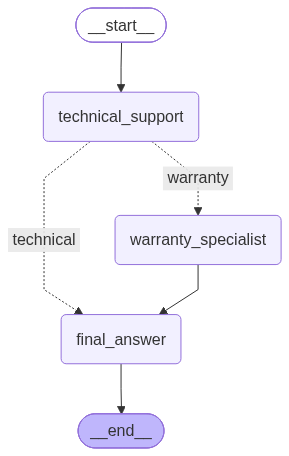


 Warranty specialist internal workflow


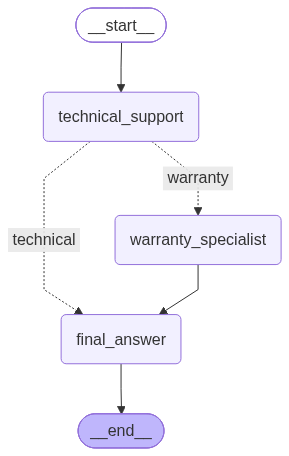

In [18]:
from langchain_core.runnables.graph import MermaidDrawMethod

for name, workflow in [
    ("Main support workflow", graph),
    ("Warranty specialist internal workflow", warranty_graph),
]:
    print("\n", name)
    try:
        img_bytes = graph.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API
        )
        display(Image(img_bytes))
    except Exception as exc:
        print("PNG rendering unavailable:", type(exc).__name__)
        print(workflow.get_graph().draw_mermaid())
        

## 10. Exercises

1. **Direct resolution:** Ask about `E102` on `PRINTER-1001`. Confirm the agent gives approved phone instructions and **does not call** `check_warranty`.
2. **Escalation:** Ask about `E900` on `PRINTER-2001`. Confirm the first agent routes to warranty review and the specialist uses the API.
3. **Failure by default:** Say only “My `PRINTER-1001` has stopped working.” Confirm the warranty path is selected.
4. **No device ID:** Say “My printer is dead.” The warranty specialist should ask for the device ID without inventing coverage.
5. **Unknown record:** Ask about `UNKNOWN-9999`. Confirm the answer says **unverified**, not **expired**.
6. **Prompt experiment:** Change the policy so `E205` must be escalated if the customer already attempted the approved update and it failed. Compare routes before and after.

### Suggested solution


In [ ]:
exercise_questions = [
    "PRINTER-1001 shows E102. Can you guide me?",
    "PRINTER-2001 shows E900 and won't power on.",
    "My PRINTER-1001 has stopped working.",
    "My printer is dead.",
    "UNKNOWN-9999 is broken. Is it under warranty?",
]

for question in exercise_questions:
    result = graph.invoke({"question": question})
    print("\nQUESTION:", question)
    print("ROUTE:", result["route"])
    print("TOOLS:", result.get("tools_used", []))
    print("ANSWER:", result["draft"])
